# 03 — LSTM sales experiment

Saved outputs are historical results from the supplied notebooks. Edited cells have cleared outputs. Run in order from a fresh kernel to reproduce; **Run All in notebooks 02 and 03 retrains models**. Keep your existing models and predictions.

The matched comparison requires `reports/tables/blend_validation_predictions.csv` from notebook 02. Customer forecasting is now in notebook 04.


In [ ]:
import sys
import importlib.util
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)

for package in ["numpy", "pandas", "matplotlib",
                "sklearn", "statsmodels", "torch", "tensorflow"]:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if available else 'Not installed'}")

# Find the project root from the notebook's working directory.
current_dir = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "data" / "train.csv").is_file()
    ),
    None,
)

if project_dir is None:
    raise FileNotFoundError(
        "Cannot locate the project root. "
        "Open this notebook inside your P6 project folder."
    )

print("\nProject folder:", project_dir)

In [2]:
%pip install statsmodels
%pip install torch --index-url https://download.pytorch.org/whl/cpu

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------- -------------------------------- 2.1/11.3 MB 12.0 MB/s eta 0:00:01
   ----------- ---------------------------- 3.1/11.3 MB 7.8 MB/s eta 0:00:02
   ----------- ---------------------------- 3.1/11.3 MB 7.8 MB/s eta 0:00:02
   -------------- ------------------------- 4.2/11.3 MB 5.4 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 4.7 MB/s eta 0:00:02
   ------------------ --------------------- 5.2/11.3 MB 4.8 MB/s eta 0:00:02
   ------------------------- -------------- 7.3/11.3 MB 5.3 MB/s eta 0:00:01
   ------------------------- -------------- 7.3/11.3 MB 5.3 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 4.7 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 4.6 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 4.6 MB/s eta 0:00:01
   ------------------------------------- -- 10.5/11.3 MB 4.4 MB/s eta 0:00:01
   -


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
   ---------------------------------------- 0.0/124.0 MB ? eta -:--:--
    --------------------------------------- 2.6/124.0 MB 15.7 MB/s eta 0:00:08
   - -------------------------------------- 6.0/124.0 MB 16.0 MB/s eta 0:00:08
   -- ------------------------------------- 9.2/124.0 MB 16.0 MB/s eta 0:00:08
   --- ------------------------------------ 11.8/124.0 MB 15.1 MB/s eta 0:00:08
   ---- ----------------------------------- 15.5/124.0 MB 15.6 MB/s eta 0:00:07
   ------ --------------------------------- 19.9/124.0 MB 16.5 MB/s eta 0:00:07
   ------- -------------------------------- 24.4/124.0 MB 17.2 MB/s eta 0:00:06
   --------- ------------------------------ 28.0/124.0 MB 17.3 MB/s eta 0:00:06
   ---------- ----------------------------- 32.2/124.0 MB 17.6 MB/s eta 0:00:06
   ----------- ---------------------------- 35.1/124.0 MB 17.2 MB/s eta 0:00:06
   -------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import torch
import statsmodels
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("PyTorch version:", torch.__version__)
print("Statsmodels version:", statsmodels.__version__)

# Small computation to verify PyTorch actually works.
x = torch.tensor([1.0, 2.0, 3.0])
print("PyTorch check:", (x * 2).tolist())
print("LSTM environment ready.")

PyTorch version: 2.14.1+cpu
Statsmodels version: 0.15.0
PyTorch check: [2.0, 4.0, 6.0]
LSTM environment ready.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project, including after a kernel restart.
current_dir = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "data" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Open this notebook inside the P6 folder.")

# Find the original training CSV.
train_path = project_dir / "data" / "train.csv"

series_data = pd.read_csv(
    train_path,
    usecols=[
        "Store", "Date", "Sales", "Open",
        "Promo", "SchoolHoliday", "StateHoliday",
    ],
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"},
).sort_values(["Store", "Date"]).reset_index(drop=True)

assert not series_data.duplicated(["Store", "Date"]).any()
assert series_data["Sales"].notna().all()
assert series_data["Sales"].ge(0).all()

# Preserve recorded closed days; do not fill absent dates with zeros.
store_summary = series_data.groupby("Store").agg(
    Recorded_days=("Date", "size"),
    First_date=("Date", "min"),
    Last_date=("Date", "max"),
)
store_summary["Calendar_days"] = (
    store_summary["Last_date"] - store_summary["First_date"]
).dt.days + 1
store_summary["Missing_days_within_span"] = (
    store_summary["Calendar_days"] - store_summary["Recorded_days"]
)

# Chronological boundaries for the upcoming LSTM experiment.
# Model/scaler fitting: before 9 May.
# Early stopping: 9 May–19 June.
# Final comparison: 20 June–31 July.
lstm_validation_start = pd.Timestamp("2015-05-09")
lstm_evaluation_start = pd.Timestamp("2015-06-20")

print("Dataset shape:", series_data.shape)
print("Stores:", series_data["Store"].nunique())
print(
    "Date range:",
    series_data["Date"].min().date(),
    "to",
    series_data["Date"].max().date(),
)
print(
    "Stores with missing dates within their recorded span:",
    int(store_summary["Missing_days_within_span"].gt(0).sum()),
)
display(store_summary.head())

# Inspect one store using only the model-fitting period.
example_store = int(series_data["Store"].min())
example_series = (
    series_data.loc[
        series_data["Store"].eq(example_store)
        & series_data["Date"].lt(lstm_validation_start)
    ]
    .set_index("Date")["Sales"]
    .asfreq("D")
)

fig, ax = plt.subplots(figsize=(12, 4))
example_series.plot(ax=ax, linewidth=0.8, alpha=0.6, label="Daily sales")
example_series.rolling(28, min_periods=28).mean().plot(
    ax=ax, linewidth=2, label="28-day rolling mean"
)
ax.set_title(f"Store {example_store}: sales before LSTM validation")
ax.set_ylabel("Sales")
ax.legend()
fig.tight_layout()
plt.show()

C:\Users\mahim\AppData\Local\Temp\ipykernel_3548\1378868179.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, regression="c", autolag="AIC")
C:\Users\mahim\AppData\Local\Temp\ipykernel_3548\1378868179.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values, regression="c", autolag="AIC")
C:\Users\mahim\AppData\Local\Temp\

,Series,ADF_statistic,p_value,Lags_used,Observations,Reject_unit_root_5pct
0,Original sales,-4.340030,0.000378,21,836,True
1,First difference,-10.556875,0.000000,20,836,True
2,Weekly difference,-10.865473,0.000000,20,830,True


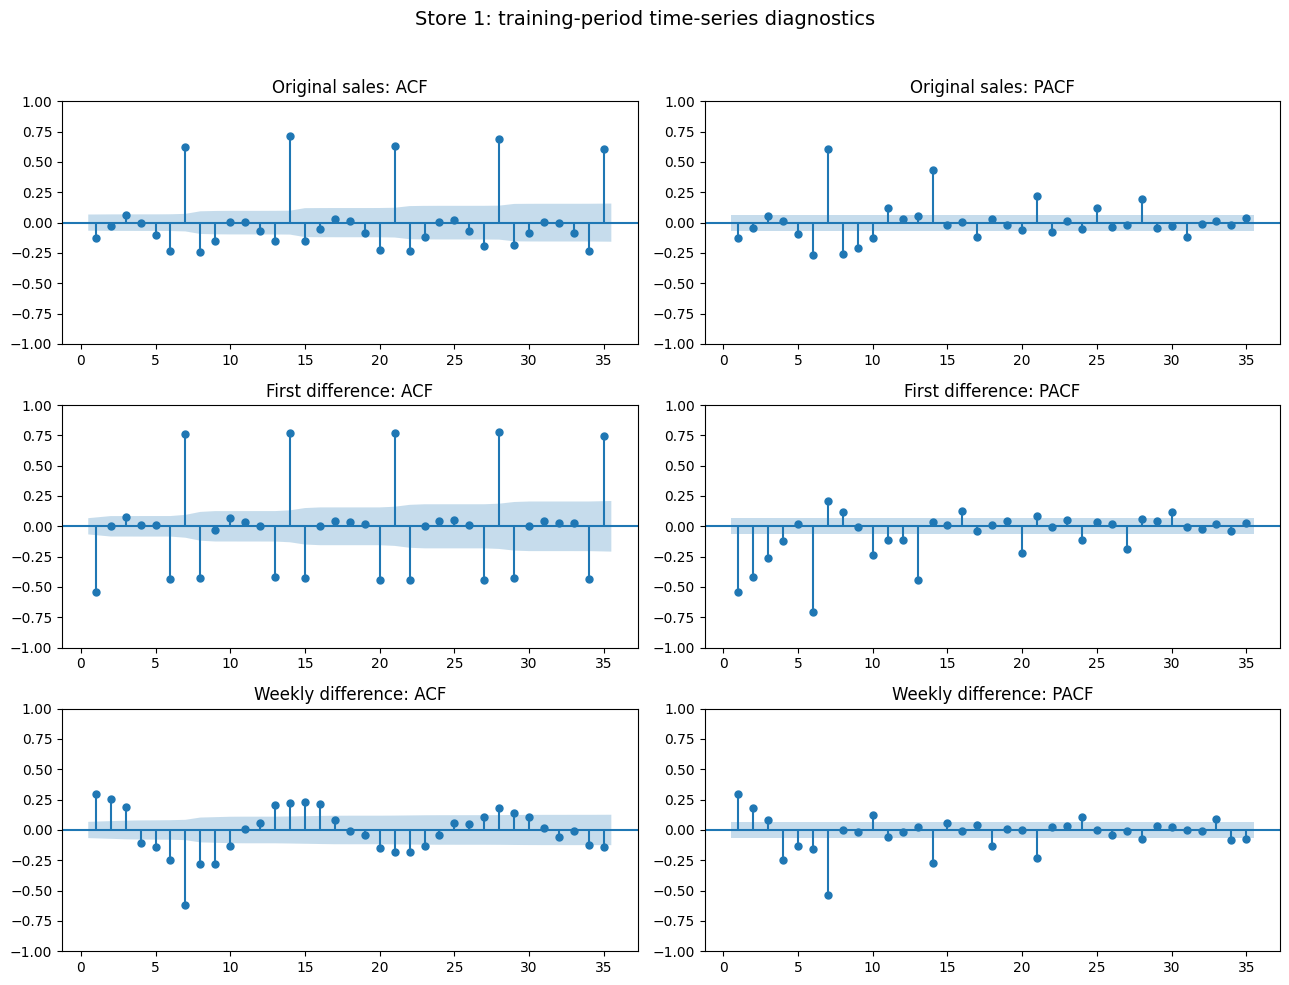

Training-period diagnostics saved.


In [3]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Do not silently join observations across missing calendar dates.
assert example_series.notna().all(), (
    "The example series contains missing dates."
)

diagnostic_series = {
    "Original sales": example_series.astype(float),
    "First difference": example_series.astype(float).diff().dropna(),
    "Weekly difference": example_series.astype(float).diff(7).dropna(),
}

adf_rows = []

for name, values in diagnostic_series.items():
    result = adfuller(values, regression="c", autolag="AIC")
    adf_rows.append({
        "Series": name,
        "ADF_statistic": result[0],
        "p_value": result[1],
        "Lags_used": result[2],
        "Observations": result[3],
        "Reject_unit_root_5pct": result[1] < 0.05,
    })

adf_results = pd.DataFrame(adf_rows)
display(adf_results.round(6))

fig, axes = plt.subplots(3, 2, figsize=(13, 10))

for row, (name, values) in enumerate(diagnostic_series.items()):
    plot_acf(values, lags=35, zero=False, ax=axes[row, 0])
    plot_pacf(
        values, lags=35, zero=False,
        method="ywm", ax=axes[row, 1],
    )
    axes[row, 0].set_title(f"{name}: ACF")
    axes[row, 1].set_title(f"{name}: PACF")

fig.suptitle(
    f"Store {example_store}: training-period time-series diagnostics",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

tables_dir = project_dir / "reports" / "tables"
figures_dir = project_dir / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

adf_results.to_csv(
    tables_dir / "lstm_stationarity_diagnostics.csv",
    index=False,
)
fig.savefig(
    figures_dir / "lstm_acf_pacf_diagnostics.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Training-period diagnostics saved.")

In [4]:
from sklearn.preprocessing import MinMaxScaler
import joblib

LOOKBACK = 28
N_STORES = 50

# Select stores without consulting their validation performance.
rng = np.random.default_rng(42)
available_stores = np.sort(series_data["Store"].unique())
lstm_store_ids = np.sort(
    rng.choice(
        available_stores,
        size=min(N_STORES, len(available_stores)),
        replace=False,
    )
)

lstm_data = series_data.loc[
    series_data["Store"].isin(lstm_store_ids)
].copy()

store_scalers = {}
train_windows = []
train_targets = []
train_keys = []

for store_id, group in lstm_data.groupby("Store", sort=True):
    daily = (
        group.set_index("Date")["Sales"]
        .sort_index()
        .asfreq("D")
    )

    # Fit each scaler using only this store's training-period sales.
    fitting_values = daily.loc[
        daily.index < lstm_validation_start
    ].dropna()

    scaler = MinMaxScaler(feature_range=(-1, 1))
    scaler.fit(fitting_values.to_numpy().reshape(-1, 1))
    store_scalers[int(store_id)] = scaler

    # Preserve missing dates as NaN.
    scaled = np.full(len(daily), np.nan, dtype=np.float32)
    observed = daily.notna().to_numpy()
    scaled[observed] = scaler.transform(
        daily.loc[daily.notna()].to_numpy().reshape(-1, 1)
    ).ravel().astype(np.float32)

    for position in range(LOOKBACK, len(daily)):
        target_date = daily.index[position]

        if target_date >= lstm_validation_start:
            break

        # 28 historical days followed by the next day's target.
        window_and_target = scaled[
            position - LOOKBACK:position + 1
        ]

        # Skip any sequence crossing missing observations.
        if not np.isfinite(window_and_target).all():
            continue

        train_windows.append(window_and_target[:-1].copy())
        train_targets.append(window_and_target[-1])
        train_keys.append((int(store_id), target_date))

X_lstm_train = np.asarray(
    train_windows, dtype=np.float32
)[..., np.newaxis]

y_lstm_train = np.asarray(
    train_targets, dtype=np.float32
).reshape(-1, 1)

lstm_train_keys = pd.DataFrame(
    train_keys, columns=["Store", "Target_date"]
)

assert len(X_lstm_train) > 0
assert X_lstm_train.shape[1:] == (LOOKBACK, 1)
assert np.isfinite(X_lstm_train).all()
assert np.isfinite(y_lstm_train).all()
assert lstm_train_keys["Target_date"].max() < lstm_validation_start

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "store_ids": lstm_store_ids.tolist(),
        "lookback": LOOKBACK,
        "scalers": store_scalers,
        "scaler_fit_end": "2015-05-08",
        "target": "Next-day sales level",
    },
    models_dir / "lstm_preprocessing.joblib",
)

print("Selected stores:", len(lstm_store_ids))
print("Training inputs:", X_lstm_train.shape)
print("Training targets:", y_lstm_train.shape)
print(
    "Training target dates:",
    lstm_train_keys["Target_date"].min().date(),
    "to",
    lstm_train_keys["Target_date"].max().date(),
)
print("Preprocessing saved. No model training performed.")

Selected stores: 50
Training inputs: (39804, 28, 1)
Training targets: (39804, 1)
Training target dates: 2013-01-29 to 2015-05-08
Preprocessing saved. No model training performed.


In [5]:
validation_dates = pd.date_range(
    lstm_validation_start,
    lstm_evaluation_start - pd.Timedelta(days=1),
    freq="D",
)
history_dates = pd.date_range(
    end=lstm_validation_start - pd.Timedelta(days=1),
    periods=LOOKBACK,
    freq="D",
)

validation_histories = []
validation_actuals = []
validation_open_flags = []
validation_store_ids = []
skipped_validation_stores = []

for store_id in lstm_store_ids:
    store_id = int(store_id)
    daily = (
        lstm_data.loc[lstm_data["Store"].eq(store_id)]
        .set_index("Date")
        .sort_index()
    )

    history = daily["Sales"].reindex(history_dates)
    future = daily.reindex(validation_dates)

    # Require complete history and evaluation records.
    if (
        history.isna().any()
        or future[["Sales", "Open"]].isna().any().any()
    ):
        skipped_validation_stores.append(store_id)
        continue

    scaled_history = store_scalers[store_id].transform(
        history.to_numpy().reshape(-1, 1)
    )

    validation_histories.append(scaled_history)
    validation_actuals.append(future["Sales"].to_numpy())
    validation_open_flags.append(future["Open"].to_numpy())
    validation_store_ids.append(store_id)

if not validation_store_ids:
    raise ValueError("No stores have complete validation histories.")

X_lstm_validation_start = np.asarray(
    validation_histories, dtype=np.float32
)
y_lstm_validation_actual = np.asarray(
    validation_actuals, dtype=np.float32
)
lstm_validation_open = np.asarray(
    validation_open_flags, dtype=np.float32
)

assert len(validation_dates) == 42
assert X_lstm_validation_start.shape[1:] == (LOOKBACK, 1)
assert np.isfinite(X_lstm_validation_start).all()
assert np.isfinite(y_lstm_validation_actual).all()
assert np.isin(lstm_validation_open, [0, 1]).all()

print("Validation stores:", len(validation_store_ids))
print("Starting histories:", X_lstm_validation_start.shape)
print("Actual sales for scoring:", y_lstm_validation_actual.shape)
print(
    "Forecast period:",
    validation_dates.min().date(),
    "to",
    validation_dates.max().date(),
)
print("Stores excluded for missing records:", skipped_validation_stores)
print("Validation block ready. No training performed.")

Validation stores: 50
Starting histories: (50, 28, 1)
Actual sales for scoring: (50, 42)
Forecast period: 2015-05-09 to 2015-06-19
Stores excluded for missing records: []
Validation block ready. No training performed.


In [6]:
import copy
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(4)

class SalesLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=32,
            num_layers=2,
            batch_first=True,
            dropout=0.1,
        )
        self.output = nn.Linear(32, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        return self.output(sequence_output[:, -1, :])


# Forecast recursively: feed predictions back into the history.
def recursive_lstm_forecast(model, starting_histories, open_flags,
                            store_ids, scalers):
    model.eval()

    histories = torch.tensor(
        starting_histories, dtype=torch.float32
    ).clone()

    scales = np.array([
        scalers[int(s)].scale_[0] for s in store_ids
    ])
    offsets = np.array([
        scalers[int(s)].min_[0] for s in store_ids
    ])

    forecasts = np.zeros(open_flags.shape, dtype=np.float64)

    with torch.no_grad():
        for day in range(open_flags.shape[1]):
            scaled_prediction = model(histories).squeeze(1).numpy()

            # Reverse each store's MinMax transformation.
            sales_prediction = np.maximum(
                (scaled_prediction - offsets) / scales, 0
            )
            sales_prediction[open_flags[:, day] == 0] = 0.0

            if not np.isfinite(sales_prediction).all():
                raise ValueError("Non-finite forecast encountered.")

            forecasts[:, day] = sales_prediction

            # Feed the adjusted prediction back, including closed-day zeros.
            next_scaled = sales_prediction * scales + offsets
            next_step = torch.tensor(
                next_scaled, dtype=torch.float32
            ).reshape(-1, 1, 1)

            histories = torch.cat(
                [histories[:, 1:, :], next_step], dim=1
            )

    return forecasts


train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_lstm_train),
        torch.from_numpy(y_lstm_train),
    ),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

lstm_model = SalesLSTM()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
loss_function = nn.MSELoss()

MAX_EPOCHS = 20
PATIENCE = 4
best_rmspe = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0
training_history = []

positive_sales = y_lstm_validation_actual > 0
assert positive_sales.any()

checkpoint_path = models_dir / "lstm_best.pt"
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    lstm_model.train()
    total_loss = 0.0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = lstm_model(batch_x)
        loss = loss_function(predictions, batch_y)

        if not torch.isfinite(loss):
            raise ValueError("Training loss became non-finite.")

        loss.backward()
        nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(batch_x)

    train_mse = total_loss / len(train_loader.dataset)

    validation_predictions = recursive_lstm_forecast(
        lstm_model,
        X_lstm_validation_start,
        lstm_validation_open,
        validation_store_ids,
        store_scalers,
    )

    actual = y_lstm_validation_actual.astype(np.float64)
    validation_rmspe = float(
        100 * np.sqrt(np.mean(
            (
                (validation_predictions[positive_sales]
                 - actual[positive_sales])
                / actual[positive_sales]
            ) ** 2
        ))
    )

    training_history.append({
        "Epoch": epoch,
        "Training_scaled_MSE": train_mse,
        "Validation_42day_RMSPE_pct": validation_rmspe,
        "Seconds": time.perf_counter() - epoch_start,
    })

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.5f} | "
        f"42-day validation RMSPE: {validation_rmspe:.2f}% | "
        f"{training_history[-1]['Seconds']:.1f}s",
        flush=True,
    )

    if validation_rmspe < best_rmspe:
        best_rmspe = validation_rmspe
        best_epoch = epoch
        best_state = copy.deepcopy(lstm_model.state_dict())
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "architecture": {
                "input_size": 1,
                "hidden_size": 32,
                "num_layers": 2,
                "dropout": 0.1,
            },
            "lookback": LOOKBACK,
            "best_epoch": best_epoch,
            "validation_rmspe_pct": best_rmspe,
            "training_end": "2015-05-08",
            "store_ids": [int(s) for s in lstm_store_ids],
        }, checkpoint_path)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: no improvement for 4 epochs.")
        break

lstm_model.load_state_dict(best_state)
lstm_model.eval()

lstm_training_history = pd.DataFrame(training_history)
lstm_training_history.to_csv(
    tables_dir / "lstm_training_history.csv", index=False
)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation RMSPE: {best_rmspe:.2f}%")
print(
    "Total time:",
    round((time.perf_counter() - training_start) / 60, 2),
    "minutes",
)
print("Best model saved:", checkpoint_path)

Epoch 01/20 | Train MSE: 0.18544 | 42-day validation RMSPE: 36.55% | 5.8s
Epoch 02/20 | Train MSE: 0.15715 | 42-day validation RMSPE: 36.85% | 5.4s
Epoch 03/20 | Train MSE: 0.10597 | 42-day validation RMSPE: 27.54% | 7.2s
Epoch 04/20 | Train MSE: 0.09027 | 42-day validation RMSPE: 33.73% | 7.3s
Epoch 05/20 | Train MSE: 0.08873 | 42-day validation RMSPE: 31.73% | 8.8s
Epoch 06/20 | Train MSE: 0.08680 | 42-day validation RMSPE: 29.06% | 6.4s
Epoch 07/20 | Train MSE: 0.08355 | 42-day validation RMSPE: 33.29% | 5.8s
Early stopping: no improvement for 4 epochs.

Best epoch: 3
Best validation RMSPE: 27.54%
Total time: 0.78 minutes
Best model saved: D:\DigiCrome Academy\Internship\Nexthikes\P6\models\lstm_best.pt


In [7]:
evaluation_dates = pd.date_range("2015-06-20", "2015-07-31")
evaluation_history_dates = pd.date_range(
    end="2015-06-19", periods=LOOKBACK
)

eval_histories = []
eval_actuals = []
eval_open_flags = []
eval_store_ids = []
seasonal_predictions = []
skipped_eval_stores = []

for store_id in lstm_store_ids:
    store_id = int(store_id)
    daily = (
        lstm_data.loc[lstm_data["Store"].eq(store_id)]
        .set_index("Date")
        .sort_index()
    )

    history = daily["Sales"].reindex(evaluation_history_dates)
    future = daily.reindex(evaluation_dates)

    if (
        history.isna().any()
        or future[["Sales", "Open"]].isna().any().any()
    ):
        skipped_eval_stores.append(store_id)
        continue

    eval_histories.append(
        store_scalers[store_id].transform(
            history.to_numpy().reshape(-1, 1)
        )
    )
    eval_actuals.append(future["Sales"].to_numpy())
    eval_open_flags.append(future["Open"].to_numpy())
    eval_store_ids.append(store_id)

    # Repeat the last observed week's sales for all six weeks.
    # No actual sales from the forecast period are used.
    seasonal = np.tile(history.to_numpy()[-7:], 6).astype(float)
    seasonal[future["Open"].to_numpy() == 0] = 0.0
    seasonal_predictions.append(seasonal)

if not eval_store_ids:
    raise ValueError("No complete evaluation histories found.")

eval_histories = np.asarray(eval_histories, dtype=np.float32)
eval_actuals = np.asarray(eval_actuals, dtype=np.float64)
eval_open_flags = np.asarray(eval_open_flags, dtype=np.float32)
seasonal_predictions = np.asarray(seasonal_predictions)

# Reload the best checkpoint rather than using the last epoch.
checkpoint = torch.load(
    models_dir / "lstm_best.pt",
    map_location="cpu",
    weights_only=True,
)
lstm_model.load_state_dict(checkpoint["model_state_dict"])

lstm_eval_predictions = recursive_lstm_forecast(
    lstm_model,
    eval_histories,
    eval_open_flags,
    eval_store_ids,
    store_scalers,
)

def forecast_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).ravel()
    predicted = np.asarray(predicted, dtype=float).ravel()
    positive = actual > 0
    return {
        "MAE": np.mean(np.abs(actual - predicted)),
        "RMSE": np.sqrt(np.mean((actual - predicted) ** 2)),
        "RMSPE_pct": 100 * np.sqrt(np.mean(
            ((actual[positive] - predicted[positive])
             / actual[positive]) ** 2
        )),
    }

lstm_evaluation_metrics = pd.DataFrame({
    "Weekly seasonal baseline": forecast_metrics(
        eval_actuals, seasonal_predictions
    ),
    "Two-layer LSTM": forecast_metrics(
        eval_actuals, lstm_eval_predictions
    ),
}).T

lstm_evaluation_results = pd.DataFrame({
    "Store": np.repeat(eval_store_ids, len(evaluation_dates)),
    "Date": np.tile(evaluation_dates.to_numpy(), len(eval_store_ids)),
    "Open": eval_open_flags.ravel(),
    "Sales": eval_actuals.ravel(),
    "Seasonal_prediction": seasonal_predictions.ravel(),
    "LSTM_prediction": lstm_eval_predictions.ravel(),
})

lstm_evaluation_metrics.to_csv(
    tables_dir / "lstm_evaluation_metrics.csv",
    index_label="Model",
)
lstm_evaluation_results.to_csv(
    tables_dir / "lstm_evaluation_predictions.csv",
    index=False,
)

print("Evaluation stores:", len(eval_store_ids))
print("Evaluation rows:", len(lstm_evaluation_results))
print("Skipped stores:", skipped_eval_stores)
display(lstm_evaluation_metrics.round(2))
print("Evaluation results saved.")

Evaluation stores: 50
Evaluation rows: 2100
Skipped stores: []


,MAE,RMSE,RMSPE_pct
Weekly seasonal baseline,1399.35,2162.78,36.16
Two-layer LSTM,1400.58,2121.93,29.28


Evaluation results saved.


,MAE,RMSE,RMSPE_pct
50–50 median + CatBoost,599.90,988.74,12.68
Two-layer LSTM,1400.58,2121.93,29.28
Weekly seasonal baseline,1399.35,2162.78,36.16


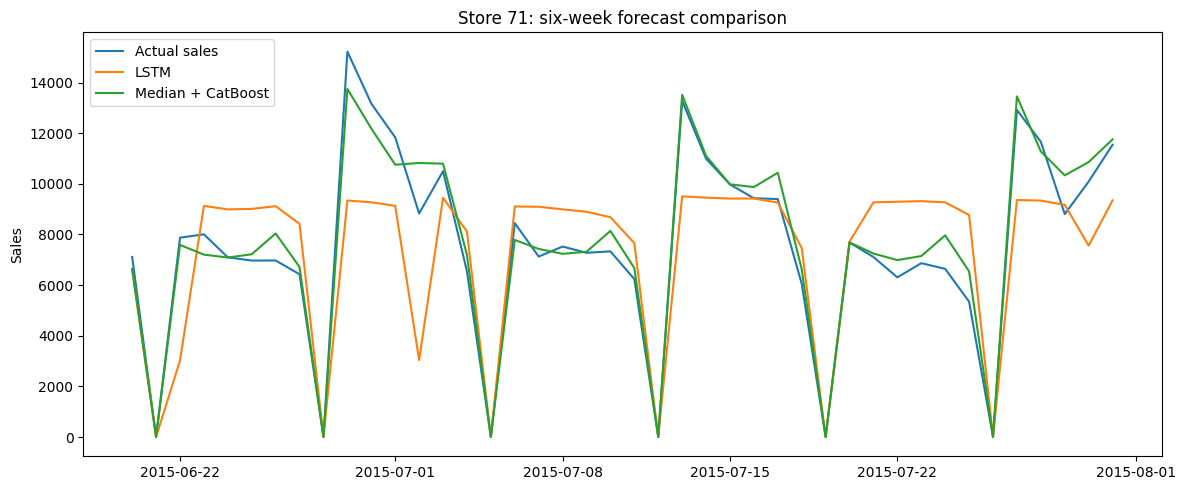

Matched comparison and example chart saved.


In [8]:
blend_saved = pd.read_csv(
    tables_dir / "blend_validation_predictions.csv",
    parse_dates=["Date"],
)

comparison_rows = lstm_evaluation_results.merge(
    blend_saved[
        ["Store", "Date", "Sales", "Blend_prediction"]
    ].rename(columns={"Sales": "Blend_actual_sales"}),
    on=["Store", "Date"],
    how="left",
    validate="one_to_one",
)

assert len(comparison_rows) == len(lstm_evaluation_results)
assert comparison_rows["Blend_prediction"].notna().all()

np.testing.assert_allclose(
    comparison_rows["Sales"],
    comparison_rows["Blend_actual_sales"],
)

comparison_columns = {
    "Weekly seasonal baseline": "Seasonal_prediction",
    "Two-layer LSTM": "LSTM_prediction",
    "50–50 median + CatBoost": "Blend_prediction",
}

matched_model_comparison = pd.DataFrame({
    name: forecast_metrics(
        comparison_rows["Sales"],
        comparison_rows[column],
    )
    for name, column in comparison_columns.items()
}).T.sort_values("RMSPE_pct")

display(matched_model_comparison.round(2))

matched_model_comparison.to_csv(
    tables_dir / "matched_store_model_comparison.csv",
    index_label="Model",
)
comparison_rows.to_csv(
    tables_dir / "matched_store_predictions.csv",
    index=False,
)

# Show a predetermined store, rather than selecting the best result.
plot_store = min(eval_store_ids)
plot_data = comparison_rows.loc[
    comparison_rows["Store"].eq(plot_store)
].sort_values("Date")

fig, ax = plt.subplots(figsize=(12, 5))

for column, label in [
    ("Sales", "Actual sales"),
    ("LSTM_prediction", "LSTM"),
    ("Blend_prediction", "Median + CatBoost"),
]:
    ax.plot(plot_data["Date"], plot_data[column], label=label)

ax.set_title(f"Store {plot_store}: six-week forecast comparison")
ax.set_ylabel("Sales")
ax.legend()
fig.tight_layout()
fig.savefig(
    figures_dir / "lstm_vs_blend_example.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Matched comparison and example chart saved.")

In [7]:
import json
from datetime import datetime, timezone

lstm_metadata = {
    "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_file": "lstm_best.pt",
    "preprocessing_file": "lstm_preprocessing.joblib",
    "architecture": {
        "input_size": 1,
        "hidden_size": 32,
        "num_layers": 2,
        "dropout": 0.1,
        "lookback_days": 28,
    },
    "training_end": "2015-05-08",
    "validation_period": ["2015-05-09", "2015-06-19"],
    "evaluation_period": ["2015-06-20", "2015-07-31"],
    "best_epoch": int(checkpoint["best_epoch"]),
    "evaluation_stores": [int(s) for s in eval_store_ids],
    "evaluation_rows": int(len(comparison_rows)),
    "forecast_horizon_days": 42,
    "forecast_method": "Recursive forecasting using predicted sales",
    "closed_day_rule": "Set predictions to zero when Open=0",
    "matched_comparison": json.loads(
        matched_model_comparison.to_json(orient="index")
    ),
    "decision": "Retain median + CatBoost blend for final sales forecasts",
    "limitations": [
        "LSTM experiment covers 50 stores.",
        "LSTM inputs contain historical sales only.",
        "LSTM and blend use different features and training cutoffs.",
        "Evaluation covers 42 days; final test horizon is 48 days.",
    ],
}

metadata_path = project_dir / "models" / "lstm_metadata.json"
metadata_path.write_text(
    json.dumps(lstm_metadata, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("LSTM experiment metadata saved:", metadata_path)
print("No retraining performed.")

LSTM experiment metadata saved: D:\DigiCrome Academy\Internship\Nexthikes\P6\models\lstm_metadata.json
No retraining performed.
